In [1]:
# import all libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# directory Analysis
path=os.listdir("/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/Dataset")

# Spiliting Data

In [5]:

# import os
# import shutil
# from sklearn.model_selection import train_test_split

# # Original dataset path
# data_dir = "/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/Dataset"

# # New output path
# output_dir = "/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/cricket_split"

# # Train aur val folders create karna
# for split in ["train", "val"]:
#     os.makedirs(os.path.join(output_dir, split), exist_ok=True)

# # Har cricketer ka folder read karna
# for cricketer in os.listdir(data_dir):

#     cricketer_path = os.path.join(data_dir, cricketer)

#     if not os.path.isdir(cricketer_path):
#         continue

#     # Images ki list
#     images = [
#         img for img in os.listdir(cricketer_path)
#         if img.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
#     ]

#     # Train 80%, Validation 20%
#     train_images, val_images = train_test_split(
#         images,
#         test_size=0.2,
#         random_state=42
#     )

#     # Class-wise folders create karna
#     for split in ["train", "val"]:
#         os.makedirs(
#             os.path.join(output_dir, split, cricketer),
#             exist_ok=True
#         )

#     # Training images copy karna
#     for img in train_images:
#         shutil.copy2(
#             os.path.join(cricketer_path, img),
#             os.path.join(output_dir, "train", cricketer, img)
#         )

#     # Validation images copy karna
#     for img in val_images:
#         shutil.copy2(
#             os.path.join(cricketer_path, img),
#             os.path.join(output_dir, "val", cricketer, img)
#         )

#     print(f"{cricketer}: Train={len(train_images)}, Val={len(val_images)}")

# print("Bhai, Dataset splitting complete ho gayi!")


# Folder Path Analysis


Yuzvendra Chahal Distribution: 38
Shubman Gill Distribution: 43
Suryakumar Yadav Distribution: 44
Venkatesh  Iyer Distribution: 44
KL Rahul Distribution: 44
Rohit Sharma Distribution: 49
Rishabh Pant Distribution: 44
Mohd Siraj Distribution: 44
Jasprit Bumrah Distribution: 44
Ravindra Jadeja Distribution: 44
Hardik Pandya Distribution: 44


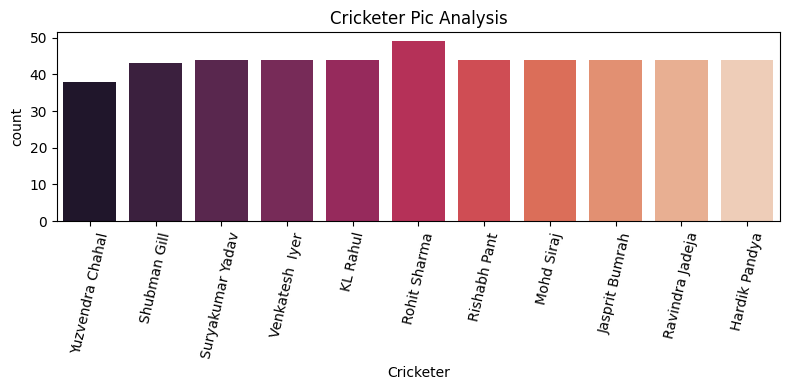

In [6]:
# train_path_analysis
images=[]
labels=[]

train_path=os.listdir("/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/cricket_split/train")

# Check distribution of training path
for file in train_path:
  distribution=len(os.listdir(os.path.join("/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/cricket_split/train",file)))
  print(f"{file} Distribution: {distribution}")

  images.append(distribution)
  labels.append(file)

#visualizatoin
plt.figure(figsize=(8,4))
sns.barplot(
    x=labels,
    y=images,
    palette="rocket"
)
plt.title("Cricketer Pic Analysis")
plt.xlabel("Cricketer")
plt.ylabel("count")
plt.xticks(rotation=77)

plt.tight_layout()
plt.show()


Yuzvendra Chahal : - 10
Shubman Gill : - 11
Suryakumar Yadav : - 11
Venkatesh  Iyer : - 11
KL Rahul : - 12
Rohit Sharma : - 13
Rishabh Pant : - 11
Mohd Siraj : - 11
Jasprit Bumrah : - 12
Ravindra Jadeja : - 12
Hardik Pandya : - 11


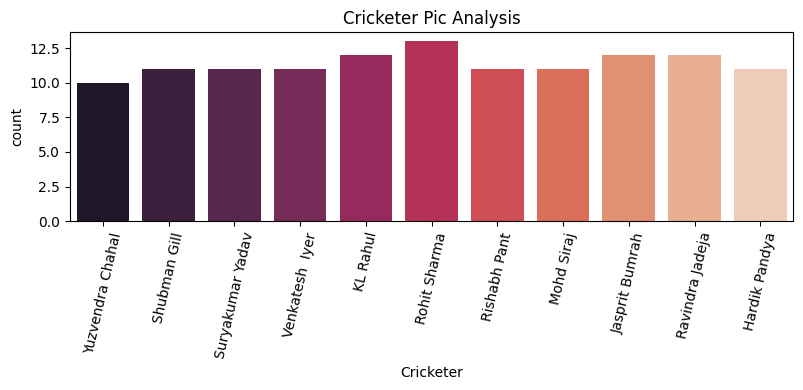

In [7]:
# val_path_analysis

images=[]
labels=[]

val_path=os.listdir("/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/cricket_split/val")

for file in val_path:
  distribution_val=len(os.listdir(os.path.join("/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/cricket_split/val",file)))
  print(f"{file} : - {distribution_val}")

  images.append(distribution_val)
  labels.append(file)

# visualization
plt.figure(figsize=(8,4))
sns.barplot(
    x=labels,
    y=images,

    palette="rocket"
)
plt.title("Cricketer Pic Analysis")
plt.xlabel("Cricketer")
plt.ylabel("count")
plt.xticks(rotation=77)

plt.tight_layout()
plt.show()

# Load the data

In [8]:
# import libraries
import tensorflow as tf
from tensorflow import keras

train_datagen=tf.keras.utils.image_dataset_from_directory(
    directory="/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/cricket_split/train",
    image_size=(224,224),
    label_mode='int',
    seed=42,
    batch_size=32,
    shuffle=True
)

val_datagen=tf.keras.utils.image_dataset_from_directory(
    directory="/content/drive/My Drive/Deep Learning Project/Cricketer_pic_detection_project/cricket_split/val",
    image_size=(224,224),
    label_mode='int',
    seed=42,
    batch_size=32,
    shuffle=False
)


Found 482 files belonging to 11 classes.
Found 125 files belonging to 11 classes.


# Display Some images


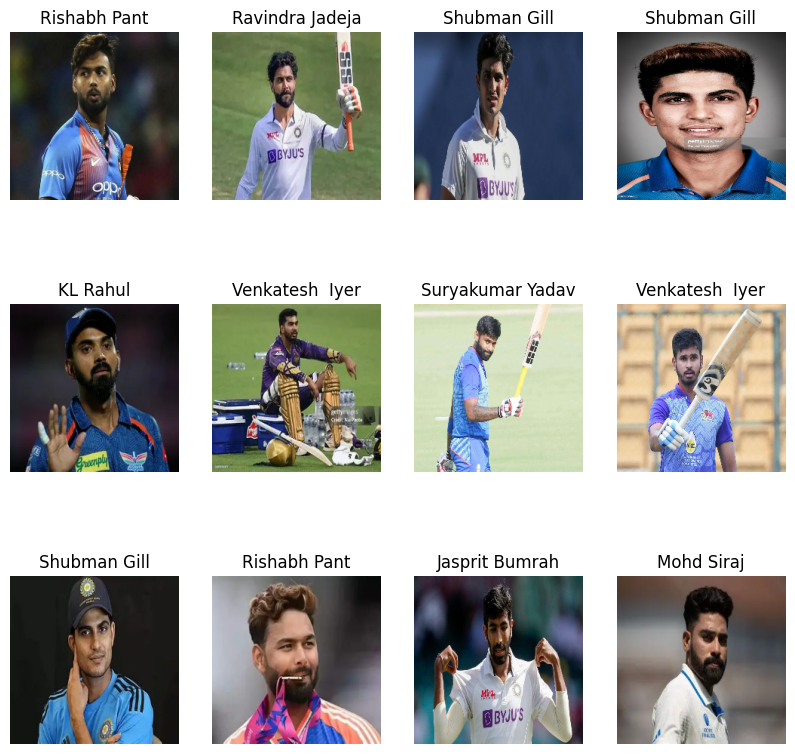

In [9]:
# display images

class_names=train_datagen.class_names

for image,label in train_datagen.take(1):
  plt.figure(figsize=(10,10))
  for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(image[i].numpy().astype("uint8"))
    plt.title(class_names[label[i]])
    plt.axis("off")

# Model Building

In [10]:
from keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Dropout,BatchNormalization,Rescaling,Input,GlobalAveragePooling2D, Dense, Dropout
from keras.models import Sequential
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomWidth
from keras.applications import EfficientNetB0,MobileNetV2

In [11]:
# data augmentation

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.2),
    RandomZoom(0.2),
    RandomWidth(0.2)
])

In [12]:
# model building

model=Sequential()

# add input layer
model.add(Input(shape=(224,224,3)))

# add data augmentation
model.add(data_augmentation)

# rescale the image
model.add(Rescaling(1./255))

# add Convolutional Layer
model.add(Conv2D(64,(3,3),padding="same",activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D((2,2),padding="same"))

model.add(Conv2D(128,(3,3),padding="same",activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D((2,2),padding="same"))

model.add(Conv2D(256,(3,3),activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))

# add feedforward network
model.add(GlobalAveragePooling2D())

model.add(Dense(128,activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.4))

model.add(Dense(64,activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.4))

# add output layer
model.add(Dense(11,activation="softmax"))


In [13]:
# summary of model
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, None, 3)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, None, 3)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, None, 64)  │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, None, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, None, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, None, 128) │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, None, 128) │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, None, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 54, None, 256)  │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 54, None, 256)  │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 27, None, 256)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 415,243 (1.58 MB)

 Trainable params: 413,963 (1.58 MB)

 Non-trainable params: 1,280 (5.00 KB)

In [14]:
# compile the model
from tensorflow.keras.optimizers import Adam
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
# fit the model
history=model.fit(
    train_datagen,
    validation_data=val_datagen,
    epochs=10
)

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 146s 9s/step - accuracy: 0.0892 - loss: 3.4118 - val_accuracy: 0.0800 - val_loss: 2.3994
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.1203 - loss: 3.1643 - val_accuracy: 0.0960 - val_loss: 2.4052
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.1286 - loss: 2.9922 - val_accuracy: 0.1360 - val_loss: 2.3961
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 870ms/step - accuracy: 0.1162 - loss: 3.0329 - val_accuracy: 0.0880 - val_loss: 2.4447
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 836ms/step - accuracy: 0.1224 - loss: 2.9170 - val_accuracy: 0.0800 - val_loss: 2.4805
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 387ms/step - accuracy: 0.1286 - loss: 2.8868 - val_accuracy: 0.1200 - val_loss: 2.5140
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 480ms/step - accuracy: 0.1245 - loss: 2.8393 - val_accuracy: 0.0960 - val_loss: 2.6153
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 562ms/step - accuracy: 0.1203 - loss: 2.6962 - val_accuracy: 0.11

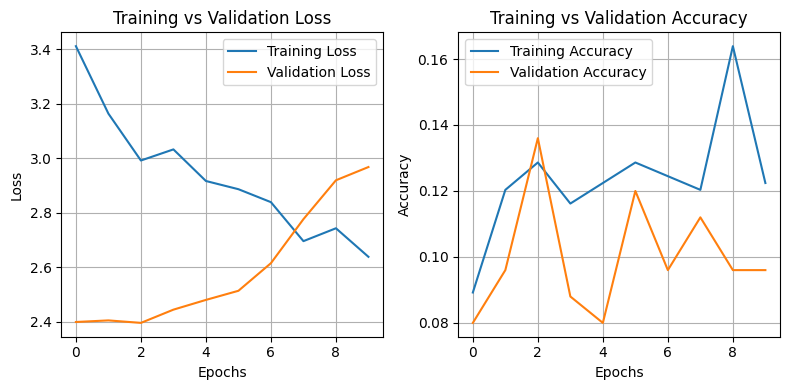

In [16]:
# training analysis

plt.figure(figsize=(8,4))
plt.subplot(121)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


plt.subplot(122)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

# Apply transfer learning

In [17]:
# define base model
base_model=MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(224,224,3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [18]:
# feature extraction technique
base_model.trainable=False

In [19]:
# build the model
from keras.regularizers import l2
model = Sequential([
    Input(shape=(224, 224, 3)),

    data_augmentation,

    # MobileNetV2 preprocessing
    Rescaling(1./112, offset=-1),

    base_model,

    GlobalAveragePooling2D(),

    Dense(128,activation="relu",kernel_regularizer=l2(0.01)),
    BatchNormalization(),
    Dropout(0.5),

    Dense(
        11,
        activation="softmax"
    )
])

In [20]:

# summary of model
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, None, 3)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, None, 3)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, None, 1280)  │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,883 (9.25 MB)

 Trainable params: 165,643 (647.04 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

In [21]:
# Add Regularizaiton technique(Callback)
from keras.callbacks import EarlyStopping,ReduceLROnPlateau

callback=EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# add it to control learning rate according to model performance
callback1=ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

In [22]:
# compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]

)

In [23]:
# fit the model
model.fit(
    train_datagen,
    validation_data=val_datagen,
    callbacks=[callback,callback1],
    epochs=40
)

Epoch 1/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 350ms/step - accuracy: 0.0954 - loss: 5.7241 - val_accuracy: 0.1360 - val_loss: 4.8823 - learning_rate: 0.0010
Epoch 2/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.1660 - loss: 4.9502 - val_accuracy: 0.1280 - val_loss: 4.7692 - learning_rate: 0.0010
Epoch 3/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 195ms/step - accuracy: 0.2635 - loss: 4.4729 - val_accuracy: 0.2080 - val_loss: 4.4331 - learning_rate: 0.0010
Epoch 4/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 216ms/step - accuracy: 0.2656 - loss: 4.2907 - val_accuracy: 0.2000 - val_loss: 4.2169 - learning_rate: 0.0010
Epoch 5/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 209ms/step - accuracy: 0.2697 - loss: 4.0172 - val_accuracy: 0.2400 - val_loss: 4.0811 - learning_rate: 0.0010
Epoch 6/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step - accuracy: 0.3838 - loss: 3.7533 - val_accuracy: 0.2720 - val_loss: 4.0151 - learning_rate: 0.0010
Epoch 7/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 208ms/step - accuracy: 0.3859 - loss: 3.6753 -

In [24]:
model.evaluate(val_datagen)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.2640 - loss: 3.2931


[3.2930655479431152, 0.2639999985694885]

In [25]:
for images, labels in train_datagen.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Image batch shape:", images.shape)


Minimum pixel value: 0.0
Maximum pixel value: 255.0
Image batch shape: (32, 224, 224, 3)


In [26]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Pretrained model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# First freeze the pretrained layers
base_model.trainable = False

# Build model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(11, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )
]

history = model.fit(
    train_datagen,
    validation_data=val_datagen,
    epochs=25,
    callbacks=callbacks
)

Epoch 1/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 283ms/step - accuracy: 0.0830 - loss: 2.7917 - val_accuracy: 0.1120 - val_loss: 2.4564 - learning_rate: 0.0010
Epoch 2/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 188ms/step - accuracy: 0.1535 - loss: 2.3502 - val_accuracy: 0.0960 - val_loss: 2.3983 - learning_rate: 0.0010
Epoch 3/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 187ms/step - accuracy: 0.1805 - loss: 2.2765 - val_accuracy: 0.1440 - val_loss: 2.3190 - learning_rate: 0.0010
Epoch 4/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 191ms/step - accuracy: 0.1909 - loss: 2.2634 - val_accuracy: 0.2160 - val_loss: 2.2806 - learning_rate: 0.0010
Epoch 5/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step - accuracy: 0.2365 - loss: 2.1494 - val_accuracy: 0.2320 - val_loss: 2.2738 - learning_rate: 0.0010
Epoch 6/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 176ms/step - accuracy: 0.2656 - loss: 2.1011 - val_accuracy: 0.2000 - val_loss: 2.2498 - learning_rate: 0.0010
Epoch 7/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step - accuracy: 0.2822 - loss: 2.0385 - 

In [27]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

print("Best training accuracy:",
      max(history.history["accuracy"]))

Best validation accuracy: 0.3199999928474426
Best training accuracy: 0.5290456414222717


In [28]:
import tensorflow as tf

# Unfreeze the pretrained model
base_model = model.get_layer("mobilenetv2_1.00_224")
base_model.trainable = True

# Freeze most layers; train only the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_datagen,
    validation_data=val_datagen,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            patience=2,
            factor=0.5,
            min_lr=1e-7
        )
    ]
)

Epoch 1/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 300ms/step - accuracy: 0.4896 - loss: 1.5378 - val_accuracy: 0.3040 - val_loss: 2.0147 - learning_rate: 1.0000e-05
Epoch 2/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 188ms/step - accuracy: 0.4793 - loss: 1.5075 - val_accuracy: 0.3440 - val_loss: 2.0286 - learning_rate: 1.0000e-05
Epoch 3/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 181ms/step - accuracy: 0.4938 - loss: 1.5076 - val_accuracy: 0.3840 - val_loss: 2.0204 - learning_rate: 1.0000e-05
Epoch 4/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 187ms/step - accuracy: 0.4876 - loss: 1.4983 - val_accuracy: 0.3680 - val_loss: 2.0055 - learning_rate: 5.0000e-06
Epoch 5/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 203ms/step - accuracy: 0.4896 - loss: 1.4560 - val_accuracy: 0.3600 - val_loss: 2.0125 - learning_rate: 5.0000e-06
Epoch 6/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 192ms/step - accuracy: 0.5000 - loss: 1.4296 - val_accuracy: 0.3360 - val_loss: 2.0392 - learning_rate: 5.0000e-06
Epoch 7/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step - accuracy:

# Model Evaluation

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 412ms/step
                  precision    recall  f1-score   support

   Hardik Pandya       0.80      0.36      0.50        11
  Jasprit Bumrah       0.64      0.75      0.69        12
        KL Rahul       0.14      0.17      0.15        12
      Mohd Siraj       0.33      0.09      0.14        11
 Ravindra Jadeja       0.33      0.25      0.29        12
    Rishabh Pant       0.18      0.18      0.18        11
    Rohit Sharma       0.36      0.38      0.37        13
    Shubman Gill       0.30      0.82      0.44        11
Suryakumar Yadav       0.33      0.27      0.30        11
 Venkatesh  Iyer       0.45      0.45      0.45        11
Yuzvendra Chahal       0.60      0.30      0.40        10

        accuracy                           0.37       125
       macro avg       0.41      0.37      0.36       125
    weighted avg       0.40      0.37      0.36       125



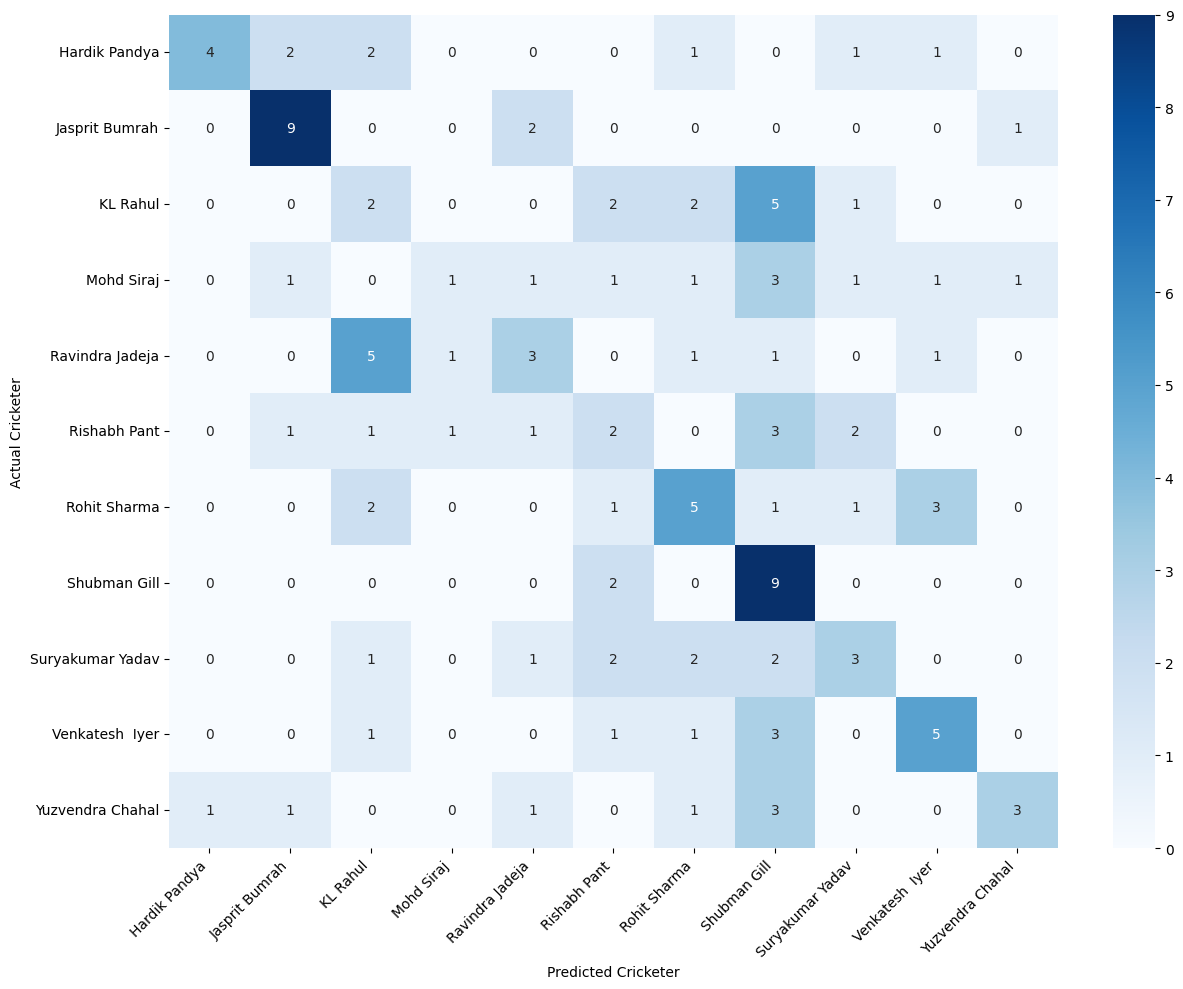

In [29]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in val_datagen
])

# Predicted labels
y_prob = model.predict(val_datagen)
y_pred = np.argmax(y_prob, axis=1)

class_names = val_datagen.class_names

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(13, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted Cricketer")
plt.ylabel("Actual Cricketer")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
# load the model
model.save("cricketer_pic_detection_model.keras")